## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets or environment variables.

In [ ]:
%%writefile attention.py
import math
from typing import Optional, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, max_seq_len: int, dropout: float = 0.1, attention_scale: float = None,
                 use_rope: bool = True, rope_base: float = 10000.0):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be evenly divisible by n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.gate_proj = nn.Linear(d_model, d_model, bias=False)

        self.use_rope = use_rope
        if use_rope:
            assert self.d_head % 2 == 0, "RoPE needs an even head dimension"
            inv_freq = 1.0 / (rope_base ** (torch.arange(0, self.d_head, 2, dtype=torch.float32) / self.d_head))
            angles = torch.arange(max_seq_len, dtype=torch.float32).unsqueeze(1) * inv_freq.unsqueeze(0)
            self.register_buffer("rope_cos", torch.cos(angles), persistent=False)
            self.register_buffer("rope_sin", torch.sin(angles), persistent=False)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
            persistent=False
        )

    def _apply_rope(self, x: torch.Tensor, start: int) -> torch.Tensor:
        T = x.size(2)
        cos = self.rope_cos[start:start + T].to(torch.float32)
        sin = self.rope_sin[start:start + T].to(torch.float32)
        x1, x2 = x[..., : self.d_head // 2].float(), x[..., self.d_head // 2:].float()
        out = torch.cat((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1)
        return out.to(x.dtype)

    def forward(
        self,
        x: torch.Tensor,
        past_kv: Optional[Tuple[torch.Tensor, torch.Tensor]] = None,
        use_cache: bool = False,
        key_padding_mask: Optional[torch.Tensor] = None,
    ):
        B, T, C = x.shape

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        q = q.view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.d_head).transpose(1, 2)

        past_len = 0
        if past_kv is not None:
            past_len = past_kv[0].size(2)

        if self.use_rope:
            q = self._apply_rope(q, past_len)
            k = self._apply_rope(k, past_len)

        if past_kv is not None:
            past_k, past_v = past_kv
            k = torch.cat([past_k, k], dim=2)
            v = torch.cat([past_v, v], dim=2)
        total_len = past_len + T
        present = (k, v) if use_cache else None

        if key_padding_mask is None and past_len == 0:
            attn_output = F.scaled_dot_product_attention(
                q, k, v,
                dropout_p=self.attn_dropout.p if self.training else 0.0,
                is_causal=True,
                scale=self.attention_scale,
            )
        else:
            attn_scores = (q @ k.transpose(-2, -1)) * self.attention_scale

            mask = self.causal_mask[past_len:total_len, :total_len]
            if key_padding_mask is not None:
                mask = mask.unsqueeze(0) & key_padding_mask.to(torch.bool).unsqueeze(1)
                mask = mask | ~mask.any(dim=-1, keepdim=True)
                mask = mask.unsqueeze(1)
            attn_scores = attn_scores.masked_fill(~mask, float("-inf"))

            attn_probs = F.softmax(attn_scores, dim=-1)
            attn_probs = self.attn_dropout(attn_probs)

            attn_output = attn_probs @ v


        attn_output = attn_output.transpose(1, 2).contiguous().view(B, T, C)
        attn_output = attn_output * torch.sigmoid(self.gate_proj(x))
        attn_output = self.out_proj(attn_output)
        attn_output = self.resid_dropout(attn_output)

        if use_cache:
            return attn_output, present
        return attn_output


Writing attention.py


In [ ]:
%%writefile model_arch.py
import math
from dataclasses import dataclass
from typing import Optional, List, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers.utils import ModelOutput
from attention import CausalSelfAttention


@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 560
    n_layers: int = 8
    n_heads: int = 8
    d_ff: int = 2240
    max_seq_len: int = 1024
    dropout: float = 0
    pos_emb_type: str = "rope"
    attention_scale: float = None
    norm_first: bool = True
    bos_token_id: int = None
    eos_token_id: int = None


@dataclass
class CausalLMOutput(ModelOutput):
    loss: Optional[torch.Tensor] = None
    logits: Optional[torch.Tensor] = None
    past_key_values: Optional[List[Tuple[torch.Tensor, torch.Tensor]]] = None


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model, dtype=torch.float32)
    pe[:, 0::2] = torch.sin(pos * div_term)
    pe[:, 1::2] = torch.cos(pos * div_term)
    return pe


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = getattr(cfg, 'norm_first', True)
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(
            d_model=cfg.d_model,
            n_heads=cfg.n_heads,
            max_seq_len=cfg.max_seq_len,
            dropout=cfg.dropout,
            attention_scale=cfg.attention_scale,
            use_rope=(cfg.pos_emb_type == "rope")
        )
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x: torch.Tensor, past_kv=None, use_cache: bool = False, key_padding_mask=None):
        if self.norm_first:
            attn_out = self.attn(self.ln1(x), past_kv=past_kv, use_cache=use_cache, key_padding_mask=key_padding_mask)
            if use_cache:
                attn_out, present = attn_out
            x = x + attn_out
            x = x + self.ffn(self.ln2(x))
        else:
            attn_out = self.attn(x, past_kv=past_kv, use_cache=use_cache, key_padding_mask=key_padding_mask)
            if use_cache:
                attn_out, present = attn_out
            x = self.ln1(x + attn_out)
            x = self.ln2(x + self.ffn(x))
        if use_cache:
            return x, present
        return x


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)

        if cfg.pos_emb_type == "sinusoidal":
            pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
            self.register_buffer("pos_emb", pe, persistent=False)

        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)

        self.head.weight = self.tok_emb.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.LayerNorm):
            torch.nn.init.ones_(module.weight)
            torch.nn.init.zeros_(module.bias)

    def forward(self, input_ids: torch.Tensor = None, labels: torch.Tensor = None, idx: torch.Tensor = None,
                past_key_values: Optional[List[Tuple[torch.Tensor, torch.Tensor]]] = None,
                use_cache: bool = False,
                attention_mask: Optional[torch.Tensor] = None,
                last_token_only: bool = False):
        if idx is None:
            idx = input_ids
        assert idx is not None, "Either input_ids or idx must be provided"

        B, T = idx.shape
        past_len = 0 if past_key_values is None else past_key_values[0][0].size(2)
        assert past_len + T <= self.cfg.max_seq_len, \
            f"Seq length {past_len + T} exceeds max sequence length {self.cfg.max_seq_len}"

        x = self.tok_emb(idx)
        if self.cfg.pos_emb_type == "sinusoidal":
            if attention_mask is None:
                x = x + self.pos_emb[past_len:past_len + T]
            else:
                pos_ids = (attention_mask.long().cumsum(dim=-1) - 1).clamp(min=0)[:, -T:]
                x = x + self.pos_emb[pos_ids]

        presents = [] if use_cache else None
        for i, block in enumerate(self.blocks):
            past_kv = None if past_key_values is None else past_key_values[i]
            if use_cache:
                x, present = block(x, past_kv=past_kv, use_cache=True, key_padding_mask=attention_mask)
                presents.append(present)
            else:
                x = block(x, past_kv=past_kv, key_padding_mask=attention_mask)

        if last_token_only:
            x = x[:, -1:, :]
        x = self.ln_f(x)
        logits = self.head(x)

        loss = None
        if labels is not None:
            shift_logits = logits[:, :-1, :].contiguous().view(-1, self.cfg.vocab_size)
            shift_labels = labels[:, 1:].contiguous().view(-1)
            loss = F.cross_entropy(shift_logits, shift_labels, ignore_index=-100)
            return CausalLMOutput(loss=loss, logits=logits, past_key_values=presents)

        if use_cache:
            return logits, presents
        return logits

    @torch.no_grad()
    def generate(self, idx: torch.Tensor, max_new_tokens: int, temperature: float = 1.0, top_p: float = 1.0, eos_token_id: int = None, attention_mask: torch.Tensor = None,
                 stop_check=None, check_every: int = 16) -> torch.Tensor:

        was_training = self.training
        self.eval()

        B = idx.size(0)
        if attention_mask is not None:
            attention_mask = attention_mask.to(device=idx.device, dtype=torch.bool)
        finished = torch.zeros(B, dtype=torch.bool, device=idx.device)

        prompt_len = idx.size(1)
        past_key_values = None
        cond_mask = None
        for step in range(max_new_tokens):
            if past_key_values is None or past_key_values[0][0].size(2) + 1 > self.cfg.max_seq_len:
                past_key_values = None
                idx_cond = idx[:, -self.cfg.max_seq_len:]
                cond_mask = None if attention_mask is None else attention_mask[:, -self.cfg.max_seq_len:]
            else:
                idx_cond = idx[:, -1:]

            logits, past_key_values = self(idx_cond, past_key_values=past_key_values, use_cache=True,
                                           attention_mask=cond_mask, last_token_only=True)
            logits = logits[:, -1, :] / max(temperature, 1e-5)

            if top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(logits, descending=True)
                cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                sorted_indices_to_remove = cumulative_probs > top_p
                sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
                sorted_indices_to_remove[..., 0] = 0
                indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
                logits = logits.masked_fill(indices_to_remove, float('-inf'))

            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)

            if eos_token_id is not None:
                idx_next = torch.where(finished.unsqueeze(1), torch.full_like(idx_next, eos_token_id), idx_next)
                finished = finished | (idx_next.squeeze(1) == eos_token_id)

            idx = torch.cat((idx, idx_next), dim=1)
            if attention_mask is not None:
                ones = torch.ones(B, 1, dtype=torch.bool, device=idx.device)
                attention_mask = torch.cat((attention_mask, ones), dim=1)
                cond_mask = torch.cat((cond_mask, ones), dim=1)

            if eos_token_id is not None and finished.all():
                break

            if stop_check is not None and (step + 1) % check_every == 0:
                satisfied = torch.as_tensor(stop_check(idx[:, prompt_len:]), dtype=torch.bool, device=idx.device)
                if (satisfied | finished).all():
                    break

        if was_training:
            self.train()
        return idx


    @staticmethod
    def _repeated_ngram_tokens(seq, n):
        if len(seq) < n - 1:
            return []
        prefix = tuple(seq[len(seq) - (n - 1):])
        banned = []
        for i in range(len(seq) - n + 1):
            if tuple(seq[i:i + n - 1]) == prefix:
                banned.append(seq[i + n - 1])
        return banned

    @torch.no_grad()
    def generate_beam(self, idx: torch.Tensor, max_new_tokens: int, num_beams: int = 4, temperature: float = 1.0,
                      attention_mask: torch.Tensor = None, no_repeat_ngram_size: int = 0, banned_token_ids=None,
                      stop_check=None, check_every: int = 16) -> torch.Tensor:

        was_training = self.training
        self.eval()

        B, T = idx.shape
        nb = num_beams
        device = idx.device
        max_new_tokens = min(max_new_tokens, self.cfg.max_seq_len - T)

        if attention_mask is None:
            attention_mask = torch.ones(B, T, dtype=torch.bool, device=device)
        attention_mask = attention_mask.to(device=device, dtype=torch.bool)

        logits, past = self(idx, use_cache=True, attention_mask=attention_mask, last_token_only=True)
        past = [(k.repeat_interleave(nb, dim=0), v.repeat_interleave(nb, dim=0)) for k, v in past]
        mask = attention_mask.repeat_interleave(nb, dim=0)
        next_logits = logits[:, -1, :].repeat_interleave(nb, dim=0)

        beam_scores = torch.zeros(B, nb, device=device)
        beam_scores[:, 1:] = float("-inf")
        gen = torch.empty(B * nb, 0, dtype=torch.long, device=device)
        row_offset = (torch.arange(B, device=device) * nb).unsqueeze(1)

        for step in range(max_new_tokens):
            if step > 0:
                mask = torch.cat([mask, torch.ones(B * nb, 1, dtype=torch.bool, device=device)], dim=1)
                out, past = self(gen[:, -1:], past_key_values=past, use_cache=True,
                                 attention_mask=mask, last_token_only=True)
                next_logits = out[:, -1, :]

            log_probs = F.log_softmax(next_logits.float() / max(temperature, 1e-5), dim=-1)

            if banned_token_ids:
                log_probs[:, banned_token_ids] = float("-inf")

            if no_repeat_ngram_size > 0 and gen.size(1) >= no_repeat_ngram_size - 1:
                for r, seq in enumerate(gen.tolist()):
                    bad = self._repeated_ngram_tokens(seq, no_repeat_ngram_size)
                    if bad:
                        log_probs[r, bad] = float("-inf")

            vocab = log_probs.size(-1)
            scores = (beam_scores.view(-1, 1) + log_probs).reshape(B, nb * vocab)
            beam_scores, top_idx = scores.topk(nb, dim=-1)

            src_beam = (top_idx // vocab + row_offset).view(-1)
            next_tok = (top_idx % vocab).view(-1, 1)

            gen = torch.cat([gen[src_beam], next_tok], dim=1)
            past = [(k[src_beam], v[src_beam]) for k, v in past]

            if stop_check is not None and (step + 1) % check_every == 0:
                best_so_far = gen.view(B, nb, -1)[:, 0]
                satisfied = torch.as_tensor(stop_check(best_so_far), dtype=torch.bool)
                if satisfied.all():
                    break

        best = gen.view(B, nb, -1)[:, 0]
        if was_training:
            self.train()
        return torch.cat([idx, best], dim=1)


Writing model_arch.py


In [3]:
import os
from huggingface_hub import login

try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    HF_TOKEN = user_secrets.get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")

os.environ["HF_TOKEN"] = HF_TOKEN
if HF_TOKEN:
    login(token=HF_TOKEN)
    print("Hugging Face login successful.")
else:
    print("HF_TOKEN not found in secrets/environment. Continuing unauthenticated.")


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [4]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))


CUDA available: True
GPU count: 1
GPU 0: Tesla T4


## 3. Configuration

#### Training configuration with 500M token dataset distribution across 4 legal sources.

In [ ]:
import os
import random
import json
import time
import math
import zipfile
import shutil

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_MODEL_REPO = "Granth2/cs781-legal-gpt2-phase1"

DATASET_SOURCES = {
    "Phase_1_Pretraining/Train/train_acts.json": 0.10,
    "Phase_1_Pretraining/Train/train_supreme_court.json": 0.40,
    "Phase_1_Pretraining/Train/train_high_courts.json": 0.40,
    "Phase_1_Pretraining/Train/train_tribunals.json": 0.10,
}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

TOTAL_TARGET_TOKENS = 400_000_000
VAL_TOKENS = 2_000_000
TRAIN_TOKENS = TOTAL_TARGET_TOKENS - VAL_TOKENS

TRAIN_BLOCK_SIZE = 1024
EPOCHS = 1
SEED = 42
random.seed(SEED)

MODEL_CONTEXT_LENGTH = 1024
N_EMBD = 768
N_LAYER = 12
N_HEAD = 12

TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.3
TOP_P = 0.95
NUM_BEAMS = 4
NO_REPEAT_NGRAM_SIZE = 3

OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "output-final")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

HF_TOKEN_ARG = HF_TOKEN if (HF_TOKEN and str(HF_TOKEN).strip()) else None
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Configuration loaded.")
print(f"Target total dataset budget: {TOTAL_TARGET_TOKENS:,} tokens")


Configuration loaded.
Target total dataset budget: 400,000,000 tokens


## 4. Load Tokenizer

In [6]:
import os
import json
from transformers import PreTrainedTokenizer
from huggingface_hub import hf_hub_download


class MyCustomTokenizer(PreTrainedTokenizer):
    END_OF_WORD = "</w>"

    def __init__(self, vocab_file, merges_file, pad_token="<pad>", unk_token="<unk>",
                 bos_token="<s>", eos_token="</s>", **kwargs):
        with open(vocab_file, "r", encoding="utf-8") as f:
            self.vocab = json.load(f)
        self.id_to_token = {i: t for t, i in self.vocab.items()}

        self.byte_to_char = self._build_byte_to_char()
        self.char_to_byte = {c: b for b, c in self.byte_to_char.items()}

        self.merge_ranks = self._load_merges(merges_file)
        self.word_cache = {}

        kwargs.setdefault("clean_up_tokenization_spaces", False)
        super().__init__(
            pad_token=pad_token,
            unk_token=unk_token,
            bos_token=bos_token,
            eos_token=eos_token,
            **kwargs
        )

    @staticmethod
    def _build_byte_to_char():
        printable = (list(range(ord("!"), ord("~") + 1))
                     + list(range(ord("¡"), ord("¬") + 1))
                     + list(range(ord("®"), ord("ÿ") + 1)))
        byte_values = printable[:]
        char_codes = printable[:]
        extra = 0
        for b in range(256):
            if b not in printable:
                byte_values.append(b)
                char_codes.append(256 + extra)
                extra += 1
        return {b: chr(c) for b, c in zip(byte_values, char_codes)}

    def _byte_ids_to_symbol(self, text):
        symbol = ""
        for part in text.split("+"):
            if part == self.END_OF_WORD:
                symbol += part
            else:
                symbol += self.byte_to_char[int(part[2:])]
        return symbol

    def _load_merges(self, merges_file):
        pairs = []
        with open(merges_file, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line or line.startswith("#version"):
                    continue
                parts = line.split(" ")
                if len(parts) == 2:
                    pairs.append((parts[0], parts[1]))

        written_as_byte_ids = len(pairs) > 0 and pairs[0][0].startswith("b:")

        merge_ranks = {}
        for left, right in pairs:
            if written_as_byte_ids:
                left = self._byte_ids_to_symbol(left)
                right = self._byte_ids_to_symbol(right)
            merge_ranks[(left, right)] = len(merge_ranks)
        return merge_ranks

    @property
    def vocab_size(self):
        return len(self.vocab)

    def get_vocab(self):
        return self.vocab

    def _split_word(self, word):
        if word in self.word_cache:
            return self.word_cache[word]

        symbols = [self.byte_to_char[b] for b in word.encode("utf-8")] + [self.END_OF_WORD]

        while len(symbols) > 1:
            pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
            known_pairs = [p for p in pairs if p in self.merge_ranks]
            if not known_pairs:
                break

            best_pair = min(known_pairs, key=lambda p: self.merge_ranks[p])

            new_symbols = []
            i = 0
            while i < len(symbols):
                if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == best_pair:
                    new_symbols.append(best_pair[0] + best_pair[1])
                    i += 2
                else:
                    new_symbols.append(symbols[i])
                    i += 1
            symbols = new_symbols

        tokens = [s if s in self.vocab else self.unk_token for s in symbols]

        if len(self.word_cache) > 500_000:
            self.word_cache.clear()
        self.word_cache[word] = tokens
        return tokens

    def _tokenize(self, text):
        tokens = []
        for word in text.split():
            tokens.extend(self._split_word(word))
        return tokens

    def convert_tokens_to_string(self, tokens):
        byte_list = []
        for token in tokens:
            if token in self.all_special_tokens:
                continue
            word_ends = token.endswith(self.END_OF_WORD)
            if word_ends:
                token = token[:-len(self.END_OF_WORD)]
            byte_list.extend(self.char_to_byte[c] for c in token if c in self.char_to_byte)
            if word_ends:
                byte_list.append(ord(" "))
        return bytes(byte_list).decode("utf-8", errors="replace").strip()

    def _convert_token_to_id(self, token):
        return self.vocab.get(token, self.vocab.get(self.unk_token, 1))

    def _convert_id_to_token(self, index):
        return self.id_to_token.get(index, self.unk_token)

    def save_vocabulary(self, save_directory, filename_prefix=None):
        prefix = (filename_prefix + "-") if filename_prefix else ""
        vocab_file = os.path.join(save_directory, prefix + "vocab.json")
        merges_file = os.path.join(save_directory, prefix + "merges.txt")
        with open(vocab_file, "w", encoding="utf-8") as f:
            json.dump(self.vocab, f, ensure_ascii=False, indent=2)
        with open(merges_file, "w", encoding="utf-8") as f:
            f.write("#version: 0.2\n")
            for (left, right), _ in sorted(self.merge_ranks.items(), key=lambda item: item[1]):
                f.write(f"{left} {right}\n")
        return (vocab_file, merges_file)


tokenizer_repo_id = "Granth2/cs781-custom-bpe-30k-Version-10-40-40-10"
vocab_path = hf_hub_download(repo_id=tokenizer_repo_id, filename="vocab.json", token=HF_TOKEN_ARG)
merges_path = hf_hub_download(repo_id=tokenizer_repo_id, filename="merges.txt", token=HF_TOKEN_ARG)

tokenizer = MyCustomTokenizer(vocab_file=vocab_path, merges_file=merges_path)

print("Tokenizer type:", type(tokenizer).__name__)
print("Vocab size:", len(tokenizer))

vocab.json:   0%|          | 0.00/640k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/320k [00:00<?, ?B/s]

Tokenizer type: MyCustomTokenizer
Vocab size: 30000


In [7]:
print(list(tokenizer.merge_ranks.items())[:3])
print(hasattr(tokenizer, "word_cache"), hasattr(tokenizer, "_word_cache"))

[(('e', '</w>'), 0), (('t', 'h'), 1), (('s', '</w>'), 2)]
True False


In [8]:
sample_sentence = "The Hon'ble Supreme Court held that the appellant's claim is maintainable."
sample_token_ids = tokenizer.encode(sample_sentence, add_special_tokens=False)
print(len(sample_sentence.split()), len(sample_token_ids), len(tokenizer.merge_ranks))
print(tokenizer.convert_ids_to_tokens(sample_token_ids))

11 11 29842
['The</w>', "Hon'ble</w>", 'Supreme</w>', 'Court</w>', 'held</w>', 'that</w>', 'the</w>', "appellant's</w>", 'claim</w>', 'is</w>', 'maintainable.</w>']


## 5. Download Training Data From Hugging Face

In [9]:
from huggingface_hub import hf_hub_download
import subprocess, sys

# AI was used to write this piece of code
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ijson"])

downloaded_train_files = {}

for relative_path in DATASET_SOURCES.keys():
    print(f"Downloading {relative_path}...")
    local_path = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=relative_path,
        repo_type="dataset",
        token=HF_TOKEN_ARG
    )
    downloaded_train_files[relative_path] = local_path
    print(f"Downloaded to: {local_path}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 3.7 MB/s eta 0:00:00


Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

Downloaded to: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_acts.json


Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

... (3 outputs left out)

Downloaded to: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_high_courts.json


Phase_1_Pretraining/Train/train_tribunal(…): reconstructing file:   0%|          |  0.00B / 6.48GB            

Phase_1_Pretraining/Train/train_tribunal(…): downloading bytes:           |  0.00B            

Downloaded to: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_tribunals.json


## 6. Create Train and Validation Tokens Set

In [10]:
import ijson
import numpy as np
import os
import random

print("Building 100M token dataset with multi-source balancing...")

BLOCK_DIR = os.path.join(OUTPUT_DIR, "blocks")
os.makedirs(BLOCK_DIR, exist_ok=True)

train_block_files = []
val_block_files = []
random.seed(SEED)

def flush_to_disk(buffer, block_size, split, block_dir, start_idx):
    """Convert a token buffer into fixed-size .npy blocks and save to disk."""
    total_len = (len(buffer) // block_size) * block_size
    if total_len == 0:
        return [], buffer

    token_array = np.array(buffer[:total_len], dtype=np.int32)
    saved = []
    for i, start in enumerate(range(0, total_len, block_size)):
        block = token_array[start:start + block_size]
        block_path = os.path.join(block_dir, f"{split}_{start_idx + i:06d}.npy")
        np.save(block_path, block)
        saved.append(block_path)
    return saved, buffer[total_len:]

for rel_path, ratio in DATASET_SOURCES.items():
    source_target = int(TRAIN_TOKENS * ratio)
    source_val_target = int(VAL_TOKENS * ratio)
    source_file_path = downloaded_train_files[rel_path]

    print(f"\nProcessing {rel_path}")
    print(f"  Target: {source_target:,} train tokens | {source_val_target:,} val tokens")

    train_token_buffer = []
    val_token_buffer = []
    collected_train = 0
    collected_val = 0

    train_blocks_count = len(train_block_files)
    val_blocks_count = len(val_block_files)

    with open(source_file_path, "rb") as source_file:
        try:
            records = ijson.items(source_file, "item")
        except Exception:
            source_file.seek(0)
            records = ijson.kvitems(source_file, "")

        for record in records:
            text = record.get("text", "") if isinstance(record, dict) else (record if isinstance(record, str) else "")
            if not text:
                continue

            tokens = tokenizer.encode(text, add_special_tokens=False)

            is_val = (random.random() < 0.05) and (collected_val < source_val_target)

            if is_val:
                remaining = source_val_target - collected_val
                tokens_to_add = tokens[:remaining]
                val_token_buffer.extend(tokens_to_add)
                collected_val += len(tokens_to_add)
            else:
                if collected_train < source_target:
                    remaining = source_target - collected_train
                    tokens_to_add = tokens[:remaining]
                    train_token_buffer.extend(tokens_to_add)
                    collected_train += len(tokens_to_add)

            if len(train_token_buffer) >= 5_000_000:
                new_files, train_token_buffer = flush_to_disk(
                    train_token_buffer, TRAIN_BLOCK_SIZE, "train", BLOCK_DIR, train_blocks_count
                )
                train_block_files.extend(new_files)
                train_blocks_count += len(new_files)
                print(f"  Flushed train buffer — collected: {collected_train:,} / {source_target:,}")

            if len(val_token_buffer) >= TRAIN_BLOCK_SIZE * 50:
                new_files, val_token_buffer = flush_to_disk(
                    val_token_buffer, TRAIN_BLOCK_SIZE, "val", BLOCK_DIR, val_blocks_count
                )
                val_block_files.extend(new_files)
                val_blocks_count += len(new_files)

            if collected_train >= source_target and collected_val >= source_val_target:
                break

    if train_token_buffer:
        new_files, _ = flush_to_disk(
            train_token_buffer, TRAIN_BLOCK_SIZE, "train", BLOCK_DIR, train_blocks_count
        )
        train_block_files.extend(new_files)

    if val_token_buffer:
        new_files, _ = flush_to_disk(
            val_token_buffer, TRAIN_BLOCK_SIZE, "val", BLOCK_DIR, val_blocks_count
        )
        val_block_files.extend(new_files)

    print(f"  Done. Collected {collected_train:,} train tokens.")

print(f"\nTotal training blocks on disk : {len(train_block_files):,}")
print(f"Total validation blocks on disk: {len(val_block_files):,}")
print(f"Approx total train tokens     : {len(train_block_files) * TRAIN_BLOCK_SIZE:,}")

Building 100M token dataset with multi-source balancing...

Processing Phase_1_Pretraining/Train/train_acts.json
  Target: 39,800,000 train tokens | 200,000 val tokens
  Flushed train buffer — collected: 5,225,354 / 39,800,000
  Flushed train buffer — collected: 10,241,774 / 39,800,000
  Flushed train buffer — collected: 15,272,532 / 39,800,000
  Flushed train buffer — collected: 20,298,894 / 39,800,000
  Flushed train buffer — collected: 25,336,702 / 39,800,000
  Flushed train buffer — collected: 30,340,094 / 39,800,000
  Flushed train buffer — collected: 35,481,938 / 39,800,000
  Done. Collected 39,800,000 train tokens.

Processing Phase_1_Pretraining/Train/train_supreme_court.json
  Target: 159,200,000 train tokens | 800,000 val tokens
  Flushed train buffer — collected: 5,000,165 / 159,200,000
  Flushed train buffer — collected: 10,000,439 / 159,200,000
  Flushed train buffer — collected: 15,003,635 / 159,200,000
  Flushed train buffer — collected: 20,011,754 / 159,200,000
  Flushe

## 7. Create Token Blocks

In [11]:
print("Training sequences:", len(train_block_files))
print("Validation sequences:", len(val_block_files))

Training sequences: 388670
Validation sequences: 1952


## 8. Create Datasets

In [12]:
import numpy as np

if len(val_block_files) == 0:
    n_steal = max(1, len(train_block_files) // 20)
    val_block_files = train_block_files[-n_steal:]
    train_block_files = train_block_files[:-n_steal]
    print(f"Val set was empty — moved {n_steal} blocks from train to val.")

print(f"Final training blocks  : {len(train_block_files):,}")
print(f"Final validation blocks: {len(val_block_files):,}")

import torch


class BlockDataset(torch.utils.data.Dataset):
    def __init__(self, files):
        self.files = files

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        return {"input_ids": np.load(self.files[i])}

train_dataset = BlockDataset(train_block_files)
val_dataset = BlockDataset(val_block_files)

print("Train dataset:", len(train_dataset), "blocks")
print("Val dataset  :", len(val_dataset), "blocks")


Final training blocks  : 388,670
Final validation blocks: 1,952
Train dataset: 388670 blocks
Val dataset  : 1952 blocks


## 9. Define The Model

In [13]:
from model_arch import DecoderLM, LMConfig

config = LMConfig(
    vocab_size=len(tokenizer),
    max_seq_len=MODEL_CONTEXT_LENGTH,
    d_model=N_EMBD,
    n_layers=N_LAYER,
    n_heads=N_HEAD,
    d_ff=4 * N_EMBD,
    dropout=0
)

model = DecoderLM(config)
model_size = sum(p.numel() for p in model.parameters())
print(f"Scratch DecoderLM Model size: {model_size / 1e6:.2f}M parameters")


Scratch DecoderLM Model size: 115.14M parameters


In [ ]:
import torch
import numpy as np

def causal_lm_data_collator(features):
    input_ids = torch.from_numpy(np.stack([f["input_ids"] for f in features])).long()

    labels = input_ids.clone()
    return {"input_ids": input_ids, "labels": labels}

data_collator = causal_lm_data_collator
print("Custom causal LM data collator ready.")


Custom causal LM data collator ready.


## 10. Training Arguments

In [15]:
from transformers import TrainingArguments
import inspect

eval_strategy_setting = "steps" if len(val_dataset) > 0 else "no"
eval_steps_setting = 2000 if len(val_dataset) > 0 else None

training_args_kwargs = dict(
    output_dir=MODEL_OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    learning_rate=3e-4,
    weight_decay=0.1,
    warmup_steps=500,
    lr_scheduler_type="cosine",
    fp16=torch.cuda.is_available(),
    eval_strategy=eval_strategy_setting,
    eval_steps=eval_steps_setting,
    logging_steps=100,
    save_steps=1000,
    save_total_limit=2,
    seed=SEED,
    report_to="none",
    prediction_loss_only=True,
    logging_dir=os.path.join(OUTPUT_DIR, "logs"),
    save_safetensors=False,
)

# AI was used to write this piece of code
valid_argument_names = set(inspect.signature(TrainingArguments.__init__).parameters)
unsupported_argument_names = [name for name in training_args_kwargs if name not in valid_argument_names]
if unsupported_argument_names:
    print("Ignoring TrainingArguments not supported by this transformers version:", unsupported_argument_names)
training_args = TrainingArguments(**{name: value for name, value in training_args_kwargs.items() if name in valid_argument_names})


Ignoring TrainingArguments not supported by this transformers version: ['logging_dir', 'save_safetensors']


## 11. Training

In [16]:
from transformers import Trainer

class TiedWeightsTrainer(Trainer):
    """
    Saves checkpoints with torch.save as pytorch_model.bin.
    Newer transformers versions always try safetensors for non-PreTrainedModel models,
    which fails because head/embedding weights are tied (shared tensors).
    """
    def _save(self, output_dir=None, state_dict=None):
        output_dir = output_dir if output_dir is not None else self.args.output_dir
        os.makedirs(output_dir, exist_ok=True)
        if state_dict is None:
            state_dict = self.accelerator.unwrap_model(self.model).state_dict()
        torch.save(state_dict, os.path.join(output_dir, "pytorch_model.bin"))
        if self.processing_class is not None:
            self.processing_class.save_pretrained(output_dir)

trainer = TiedWeightsTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    processing_class=tokenizer
)

import math
import time
from transformers import TrainerCallback
from transformers.trainer_callback import ProgressCallback

def format_duration(sec):
    sec = int(max(sec, 0))
    return f"{sec // 3600}h {(sec % 3600) // 60:02d}m"

class PeriodicProgressPrinter(TrainerCallback):
    """Prints step / percent done / elapsed / ETA / loss / speed every `interval_sec` seconds."""
    def __init__(self, interval_sec=600):
        self.interval_sec = interval_sec

    def on_train_begin(self, args, state, control, **kwargs):
        self.start = self.last_t = time.time()
        self.start_step = self.last_step = state.global_step
        self.last_loss = None
        self.printed_first = False
        self.tokens_per_step = (args.train_batch_size * args.gradient_accumulation_steps
                                * args.world_size * TRAIN_BLOCK_SIZE)
        print(f"Training started: {state.max_steps:,} steps, {self.tokens_per_step:,} tokens per step", flush=True)

    def on_log(self, args, state, control, logs=None, **kwargs):
        logs = logs or {}
        if "loss" in logs:
            self.last_loss = logs["loss"]
        if "eval_loss" in logs:
            print(f"[step {state.global_step:,}] eval_loss={logs['eval_loss']:.4f} "
                  f"perplexity={math.exp(logs['eval_loss']):.2f}", flush=True)

    def on_step_end(self, args, state, control, **kwargs):
        now = time.time()
        done = state.global_step - self.start_step
        if self.printed_first and now - self.last_t < self.interval_sec:
            return
        if not self.printed_first and done < 20:
            return
        self.printed_first = True
        elapsed = now - self.start
        remaining = state.max_steps - state.global_step
        eta = elapsed / max(done, 1) * remaining
        tokens_per_sec = (state.global_step - self.last_step) * self.tokens_per_step / max(now - self.last_t, 1e-9)
        loss = f"{self.last_loss:.4f}" if self.last_loss is not None else "n/a"
        print(f"step {state.global_step:,}/{state.max_steps:,} ({100 * state.global_step / state.max_steps:.1f}%) | "
              f"elapsed {format_duration(elapsed)} | ETA {format_duration(eta)} | loss {loss} | {tokens_per_sec:,.0f} tokens/s", flush=True)
        self.last_t, self.last_step = now, state.global_step

    def on_train_end(self, args, state, control, **kwargs):
        print(f"Training finished at step {state.global_step:,} after {format_duration(time.time() - self.start)}", flush=True)

trainer.remove_callback(ProgressCallback)
trainer.add_callback(PeriodicProgressPrinter())

start_time = time.time()

trainer.train()

training_time = time.time() - start_time

tokens_per_epoch = len(train_dataset) * TRAIN_BLOCK_SIZE
total_tokens = tokens_per_epoch * EPOCHS
tokens_per_second = total_tokens / training_time

print(f"Training time: {training_time / 3600:.2f} hours")
print(f"Training speed: {tokens_per_second:,.0f} tokens/sec")


Training started: 48,584 steps, 8,192 tokens per step


Step,Training Loss,Validation Loss
2000,3.588426,3.418435
4000,3.057231,2.923384
6000,2.784194,2.694794
8000,2.654235,2.580323
10000,2.551725,2.500464
12000,2.562560,2.439790
14000,2.514259,2.389800
16000,2.463026,2.343067
18000,2.394096,2.300453
20000,2.386158,2.264016


step 20/48,584 (0.0%) | elapsed 0h 00m | ETA 7h 57m | loss n/a | 13,894 tokens/s
step 974/48,584 (2.0%) | elapsed 0h 10m | ETA 8h 18m | loss 4.4104 | 13,023 tokens/s
step 1,912/48,584 (3.9%) | elapsed 0h 20m | ETA 8h 13m | loss 3.6149 | 12,796 tokens/s
[step 2,000] eval_loss=3.4184 perplexity=30.52
step 2,765/48,584 (5.7%) | elapsed 0h 30m | ETA 8h 20m | loss 3.3414 | 11,634 tokens/s
step 3,699/48,584 (7.6%) | elapsed 0h 40m | ETA 8h 08m | loss 3.0915 | 12,742 tokens/s
[step 4,000] eval_loss=2.9234 perplexity=18.60
step 4,552/48,584 (9.4%) | elapsed 0h 50m | ETA 8h 05m | loss 2.9666 | 11,639 tokens/s
step 5,484/48,584 (11.3%) | elapsed 1h 00m | ETA 7h 53m | loss 2.8958 | 12,720 tokens/s
[step 6,000] eval_loss=2.6948 perplexity=14.80
step 6,337/48,584 (13.0%) | elapsed 1h 10m | ETA 7h 48m | loss 2.8163 | 11,642 tokens/s
step 7,270/48,584 (15.0%) | elapsed 1h 20m | ETA 7h 35m | loss 2.6299 | 12,735 tokens/s
[step 8,000] eval_loss=2.5803 perplexity=13.20
step 8,123/48,584 (16.7%) | elapse

## 12. Perplexity

In [17]:
eval_results = trainer.evaluate()
eval_loss = eval_results["eval_loss"]
perplexity = math.exp(eval_loss)
print(f"Validation loss: {eval_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")


[step 48,584] eval_loss=1.9902 perplexity=7.32


Training Loss,Validation Loss,Step
2.070882,1.990169,48584


Validation loss: 1.990169
Validation perplexity: 7.3168


## 13. Plot Training and Validation Loss

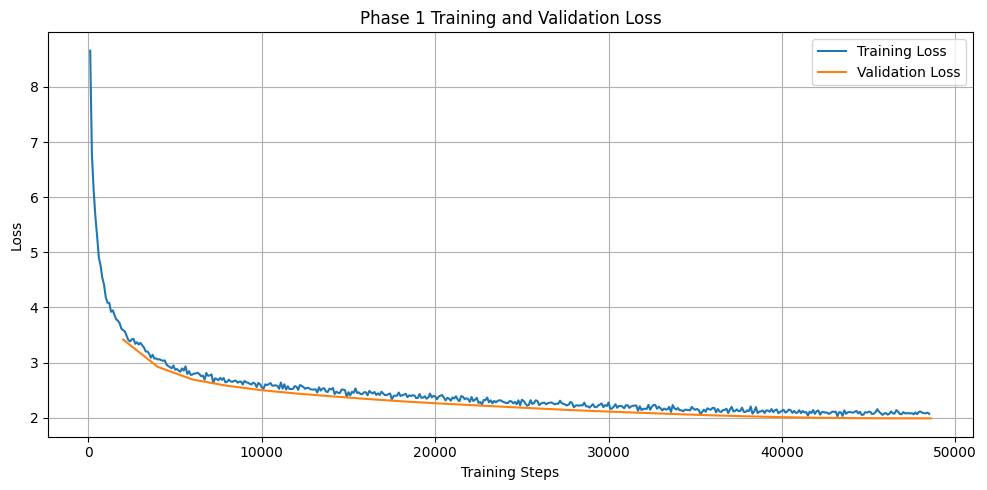

Loss plot saved to:
/kaggle/working/cs781_phase1/training_validation_loss.png


In [18]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history

train_steps = []
train_loss = []
eval_steps = []
eval_loss = []

for log in logs:
    if "loss" in log and "step" in log:
        train_steps.append(log["step"])
        train_loss.append(log["loss"])
    if "eval_loss" in log and "step" in log:
        eval_steps.append(log["step"])
        eval_loss.append(log["eval_loss"])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")
plt.plot(eval_steps, eval_loss, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:")
print(LOSS_PLOT_PATH)


## 14. Save Final Model to Kaggle Output

In [19]:
trainer.save_model(MODEL_OUTPUT_DIR)
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

print("Final model saved to:")
print(MODEL_OUTPUT_DIR)


Final model saved to:
/kaggle/working/cs781_phase1/legal-gpt2-final


## 15. Push Model to Hugging Face Hub

In [20]:
from huggingface_hub import HfApi

HF_SUBMISSION_REPO = "Granth2/cs781-phase1-Submission-9"
print(f"Uploading model weights and tokenizer to Hugging Face repository: {HF_MODEL_REPO}...")
try:
    api = HfApi()
    api.create_repo(repo_id=HF_SUBMISSION_REPO, exist_ok=True, token=HF_TOKEN_ARG)
    api.upload_folder(
        folder_path=MODEL_OUTPUT_DIR,
        repo_id=HF_SUBMISSION_REPO,
        token=HF_TOKEN_ARG
    )
    print("Model weights and tokenizer pushed successfully to Hugging Face Hub.")
except Exception as e:
    print(f"Failed to push weights to Hugging Face Hub: {e}")


Uploading model weights and tokenizer to Hugging Face repository: Granth2/cs781-legal-gpt2-phase1...
Model weights and tokenizer pushed successfully to Hugging Face Hub.


## 16. Load Test Data from HuggingFace

In [21]:
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN_ARG
)

print("Test file:", test_file_path)


test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [22]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))


Number of test examples: 1000


## 18. Load Final Model for Generation

In [23]:
from model_arch import DecoderLM, LMConfig
import torch
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generation_tokenizer = tokenizer

generation_model = DecoderLM(config)

weights_path = os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin")
if not os.path.exists(weights_path):
    weights_path = os.path.join(MODEL_OUTPUT_DIR, "model.safetensors")
    if os.path.exists(weights_path):
        from safetensors.torch import load_file
        state_dict = load_file(weights_path)
    else:
        state_dict = trainer.model.state_dict()
else:
    state_dict = torch.load(weights_path, map_location=device)

generation_model.load_state_dict(state_dict)
generation_model = generation_model.to(device)
generation_model.eval()

print("Device:", device)
print(f"Scratch DecoderLM Parameters: {sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M")


Device: cuda
Scratch DecoderLM Parameters: 115.14M


## 19. Generate 128 Words
#### (words, not tokens)

In [24]:
def generate_batch(prompts, model, tokenizer, device, target_words=128):
    predictions = []
    eos_id = getattr(tokenizer, "eos_token_id", None)
    pad_id = getattr(tokenizer, "pad_token_id", None)
    if pad_id is None:
        pad_id = eos_id if eos_id is not None else 0

    max_prompt_len = MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS

    encoded_prompts = []
    for prompt in prompts:
        input_ids = tokenizer.encode(prompt, add_special_tokens=False)
        if len(input_ids) > max_prompt_len:
            input_ids = input_ids[-max_prompt_len:]
        encoded_prompts.append(input_ids)

    longest_prompt_len = max(len(prompt_ids) for prompt_ids in encoded_prompts)
    padded_prompt_ids = torch.full((len(encoded_prompts), longest_prompt_len), pad_id, dtype=torch.long)
    attention_mask = torch.zeros((len(encoded_prompts), longest_prompt_len), dtype=torch.long)
    for i, prompt_ids in enumerate(encoded_prompts):
        if prompt_ids:
            padded_prompt_ids[i, longest_prompt_len - len(prompt_ids):] = torch.tensor(prompt_ids, dtype=torch.long)
            attention_mask[i, longest_prompt_len - len(prompt_ids):] = 1
    padded_prompt_ids = padded_prompt_ids.to(device)
    attention_mask = attention_mask.to(device)

    def enough_words(best_beams):
        has_enough_words = []
        for beam_tokens in best_beams.tolist():
            text = tokenizer.decode(beam_tokens, skip_special_tokens=True)
            has_enough_words.append(len(text.split()) >= target_words + 1)
        return has_enough_words

    banned = sorted({t for t in (pad_id, eos_id, getattr(tokenizer, "unk_token_id", None),
                                 getattr(tokenizer, "bos_token_id", None)) if t is not None})

    with torch.no_grad():
        output_ids = model.generate_beam(
            idx=padded_prompt_ids,
            max_new_tokens=MAX_GENERATION_TOKENS,
            num_beams=NUM_BEAMS,
            temperature=TEMPERATURE,
            attention_mask=attention_mask,
            no_repeat_ngram_size=NO_REPEAT_NGRAM_SIZE,
            banned_token_ids=banned,
            stop_check=enough_words,
            check_every=16
        )

    for i in range(len(encoded_prompts)):
        generated_tokens = output_ids[i, longest_prompt_len:].tolist()
        if eos_id is not None and eos_id in generated_tokens:
            generated_tokens = generated_tokens[:generated_tokens.index(eos_id) + 1]
        generated_text = tokenizer.decode(generated_tokens, skip_special_tokens=True)
        generated_words = generated_text.split()[:target_words]
        predictions.append(" ".join(generated_words))

    return predictions

## 20. Generate Predictions for the Test Set

In [25]:
predictions = {}
GENERATION_BATCH_SIZE = 8

if isinstance(test_data, dict):
    test_items = list(test_data.items())
elif isinstance(test_data, list):
    test_items = [(str(record.get("id", position + 1)), record) for position, record in enumerate(test_data)]
else:
    raise ValueError("Unrecognized test_data structure")

total_examples = len(test_items)
print(f"Total test examples: {total_examples}")

for start in range(0, total_examples, GENERATION_BATCH_SIZE):
    batch = test_items[start:start + GENERATION_BATCH_SIZE]
    batch_ids = [str(example_id) for example_id, _ in batch]
    batch_prompts = [record["text"] if isinstance(record, dict) else str(record) for _, record in batch]

    batch_predictions = generate_batch(
        prompts=batch_prompts,
        model=generation_model,
        tokenizer=generation_tokenizer,
        device=device,
        target_words=128
    )

    for example_id, prediction in zip(batch_ids, batch_predictions):
        predictions[example_id] = {"text": prediction}

    completed = start + len(batch)
    print(f"Completed {completed}/{total_examples} ({100 * completed / total_examples:.1f}%)")


Total test examples: 1000
Completed 8/1000 (0.8%)
Completed 16/1000 (1.6%)
Completed 24/1000 (2.4%)
Completed 32/1000 (3.2%)
Completed 40/1000 (4.0%)
Completed 48/1000 (4.8%)
Completed 56/1000 (5.6%)
Completed 64/1000 (6.4%)
Completed 72/1000 (7.2%)
Completed 80/1000 (8.0%)
Completed 88/1000 (8.8%)
Completed 96/1000 (9.6%)
Completed 104/1000 (10.4%)
Completed 112/1000 (11.2%)
Completed 120/1000 (12.0%)
Completed 128/1000 (12.8%)
Completed 136/1000 (13.6%)
Completed 144/1000 (14.4%)
Completed 152/1000 (15.2%)
Completed 160/1000 (16.0%)
Completed 168/1000 (16.8%)
Completed 176/1000 (17.6%)
Completed 184/1000 (18.4%)
Completed 192/1000 (19.2%)
Completed 200/1000 (20.0%)
Completed 208/1000 (20.8%)
Completed 216/1000 (21.6%)
Completed 224/1000 (22.4%)
Completed 232/1000 (23.2%)
Completed 240/1000 (24.0%)
Completed 248/1000 (24.8%)
Completed 256/1000 (25.6%)
Completed 264/1000 (26.4%)
Completed 272/1000 (27.2%)
Completed 280/1000 (28.0%)
Completed 288/1000 (28.8%)
Completed 296/1000 (29.6%)


## 21. Save prediction.json

In [26]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)


prediction.json saved:
/kaggle/working/cs781_phase1/prediction.json


## 22. Create CodaBench Submission ZIP

In [27]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)


Codabench submission created:
/kaggle/working/cs781_phase1/submission.zip
